# Random 2-SAT Phase Transition Plot Analysis
Plots showing the phase transition in random 2-SAT, made from the files in ```../results/```.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [17]:
df = pd.read_csv('../results/csv/2sat_parallelized_[500,2000]_500_10000.csv')
df.head()

,n,alpha,pr_satisfiable,avg_runtime
0,500,0.000000,1.0,0.000001
1,500,0.066667,1.0,0.000008
2,500,0.133333,1.0,0.000009
3,500,0.200000,1.0,0.000011
4,500,0.266667,1.0,0.000010


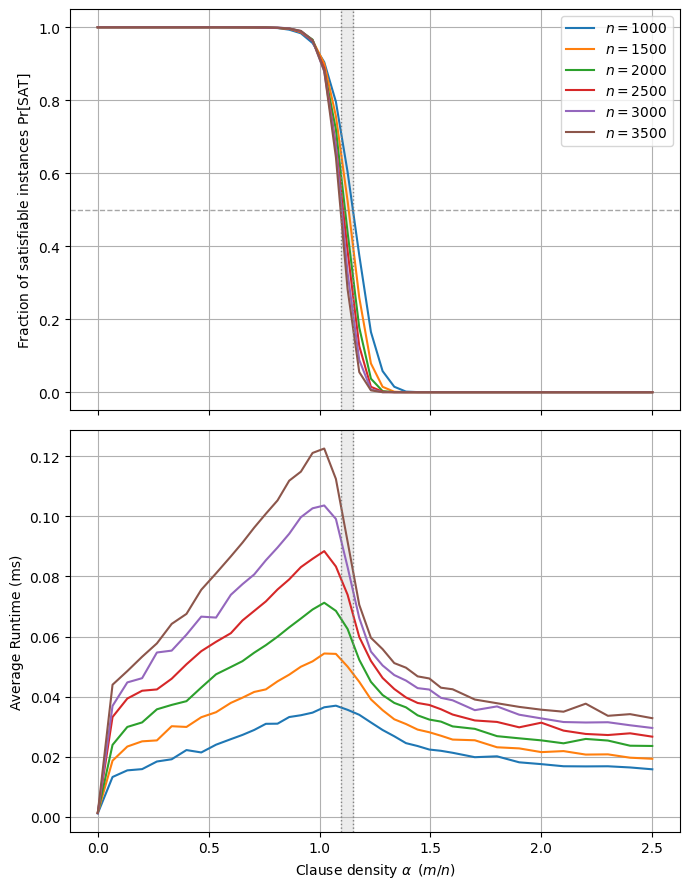

In [27]:
# for n in df['n'].unique():
#     subset = df[df['n'] == n]
#     plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'n={n}')
# plt.xlabel('alpha (m/n)')
# plt.ylabel('Pr(SAT)')
# plt.title('Phase Transition in Random 2-SAT')
# plt.legend()
# plt.grid()
# plt.show()

# Pivot data so columns are 'n' and index is 'alpha'
# pivoted = df.pivot(index='alpha', columns='n', values='pr_satisfiable')

# import numpy as np
# X, Y = np.meshgrid(pivoted.columns, pivoted.index)
# Z = pivoted.values

# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')
# surf = ax.plot_surface(Y, X, Z, cmap='viridis') # Note: Y is alpha, X is n

# ax.set_xlabel('Alpha')
# ax.set_ylabel('N')
# ax.set_zlabel('Pr(SAT)')
# fig.colorbar(surf, shrink=0.5, aspect=5)
# plt.show()

# 1. Load your raw data
df = pd.read_csv('../results/csv/2sat_parallelized_[1000,3500]_1000_10000.csv')

# Create a figure with 2 stacked subplots sharing the X-axis
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 9))

crossing_points = []

for n in sorted(df['n'].unique()):
    subset = df[df['n'] == n]
    x = subset['alpha'].values
    y_prob = subset['pr_satisfiable'].values
    y_time = subset['avg_runtime'].values * 1000  # Convert to ms
    
    # Plot Probability on top (ax1)
    ax1.plot(x, y_prob, label=fr"$n={n}$")
    
    # Plot Runtime on bottom (ax2)
    ax2.plot(x, y_time, label=fr"$n={n}$")
    
    # Interpolate to find exact alpha where Pr[SAT] = 0.5
    # np.interp requires x to be increasing, so we reverse the decreasing arrays
    alpha_cross = np.interp(0.5, y_prob[::-1], x[::-1])
    if n == 1000 or n == 3500:
        crossing_points.append(alpha_cross)

# --- VISUAL GUIDES ---
# Draw horizontal line at 0.5 on the probability plot
ax1.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, alpha=0.7)

# Shade the region between the n=50 and n=100 crossing points across BOTH plots
left_bound, right_bound = min(crossing_points), max(crossing_points)
ax1.axvspan(left_bound, right_bound, color='gray', alpha=0.15)
ax2.axvspan(left_bound, right_bound, color='gray', alpha=0.15)

# Optional: Draw faint vertical lines at the edges of the shaded region
ax1.axvline(x=left_bound, color='gray', linestyle=':', linewidth=1)
ax1.axvline(x=right_bound, color='gray', linestyle=':', linewidth=1)
ax2.axvline(x=left_bound, color='gray', linestyle=':', linewidth=1)
ax2.axvline(x=right_bound, color='gray', linestyle=':', linewidth=1)

# Formatting Top Plot (Probability)
ax1.set_ylabel(r"Fraction of satisfiable instances $\Pr[\rm SAT]$")
ax1.grid(True)
ax1.legend()

# Formatting Bottom Plot (Runtime)
ax2.set_ylabel(r"Average Runtime (ms)")
ax2.set_xlabel(r"Clause density $\alpha \,\,\, (m/n)$")
ax2.grid(True)

plt.tight_layout()
plt.show()

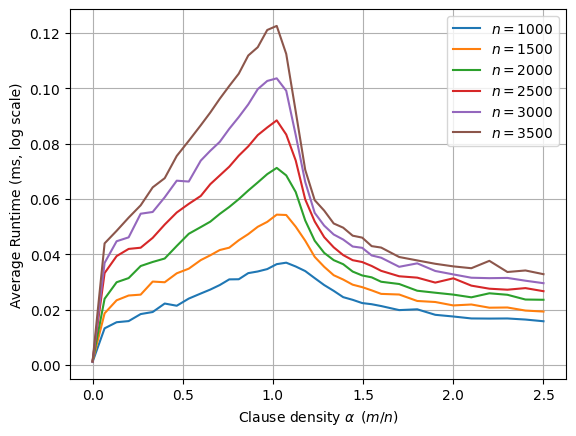

In [30]:
df['avg_runtime_ms'] = df['avg_runtime'] * 1000

for n in df['n'].unique():
    subset = df[df['n'] == n]
    plt.plot(subset['alpha'], subset['avg_runtime_ms'], label=fr"$n={n}$")
# plt.yscale('log')
plt.xlabel(r"Clause density $\alpha \,\,\, (m/n)$")
plt.ylabel("Average Runtime (ms, log scale)")
# plt.title('Solver Runtime vs Clause Density')
plt.legend()
plt.grid()
plt.show()